# JupyerLab notebook example for Pulse Structure investigations

/!\ /!\ /!\  
Oxygen diffusion from cell environment not (yet) included in the model.  
Therefore, the oxygen level is reinitialized before each new pulse.  

## Module imports

In [111]:
# External modules (to "pip install")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import simpson, cumulative_trapezoid

# Modules from Standard lib
from pathlib import Path

# RadioBio module
import radiopyo as rp
from radiopyo.physics.beam import PulsedBeam, ConstantBeam

In [2]:
from Plot_template import RPlot, FigManager
RPlot.init_rcparams()
fig_man = FigManager()

## Simulation Run

In [3]:
file = Path(rf"configuration_PULSESTRUCT.toml")
uc = rp.UnitCell.from_toml(file)

2023-07-11 15:05:51,338::radiopyo::INFO::Loading config from file: configuration_PULSESTRUCT.toml
2023-07-11 15:05:51,343::radiopyo::INFO::Resolving include: C:\Users\rtonneau\DEV\PYTHON\radiopyo\radiopyo\data\config_Labarbe.toml
2023-07-11 15:05:51,346::radiopyo::INFO::Resolving include: C:\Users\rtonneau\DEV\PYTHON\radiopyo\radiopyo\data\basic_water_radiolysis.toml
2023-07-11 15:05:51,611::radiopyo::INFO::Resolving include: C:\Users\rtonneau\DEV\PYTHON\radiopyo\radiopyo\data\reactions_biology.toml
2023-07-11 15:05:51,658::radiopyo::WARNING::Unable to compute mass of GSH. Setting it to default mass, i.e. 0
2023-07-11 15:05:51,913::radiopyo::WARNING::Unable to compute mass of GSH. Setting it to default mass, i.e. 0
2023-07-11 15:05:52,148::radiopyo::INFO::File is loaded
2023-07-11 15:05:52,148::radiopyo::INFO::Beam configuration detected in config file
2023-07-11 15:05:52,149::radiopyo::INFO::Beam PulsedBeam(dose_rate=5.0, timer=Timer(period=0.2, on_time=0.008, start_time=0.0), max_dos

## Beam maker

In [4]:
def make_beam(npulse:int, dose:float=1, adr:float=125, duty_cycle:float=20):
    if npulse < 1:
        raise ValueError("npulse must be at least 1!!")
    if npulse == 1:
        return ConstantBeam(dose_rate=adr, max_dose=dose)
    dc = duty_cycle / 100
    pdr = adr / dc # Peak dose rate
    t_tot = dose/adr
    t_on = t_tot * dc / npulse
    t_off = t_tot * (1-dc) / (npulse-1)
    return PulsedBeam.from_peak_dose_rate(
        peak_dr = pdr,
        on_time = t_on,
        period = t_on + t_off,
        n_pulse = npulse,
        )

In [5]:
make_beam(100, 1, 125, 20)

PulsedBeam(dose_rate=123.99799599198397, timer=Timer(period=8.064646464646464e-05, on_time=1.6e-05, start_time=0.0), max_dose=0.9999999999999999, nickname='', time_at_max_dose=0.008, dose_per_pulse=0.01, peak_dose_rate=625.0)

## Simulation Run LOOP

In [6]:
import itertools as it
rp.set_logging_level("ERROR")

In [75]:
for elt in range(1,10):
    print(elt)

1
2
3
4
5
6
7
8
9


In [112]:
npulse = range(1,5)
all_res = dict()
sims = dict()

beam = ConstantBeam(dose_rate=2, max_dose=1)
uc.set_beam(beam)
print(f"Simulating: Conv")
res = uc.run([1e-9, 300],atol=1e-8, rtol=1e-4, use_jac=False)
sims[0] = res.to_pandas()
all_res[0] = res

for idx, pulses in enumerate(npulse):
    print(f"Simulating: {pulses} pulse(s)")
    beam = make_beam(pulses)
    uc.set_beam(beam)
    res = uc.run([1e-9, 300],atol=1e-8, rtol=1e-4, use_jac=True)
    #res = uc.prepare_chunked_run([1e-9, 300],
    #                             #max_step_size_on=1e-7,
    #                             #max_step_size_off=1e-6,
    #                             #max_step_size_final=0.1,
    #                             atol=1e-7,
    #                             rtol=1e-3,
    #                             use_jac=False,
    #                            )
    #res = res.subdivide_last_chunk(n=10, max_step_size=0.1, scale="log")
    #res = res.run()
    sims[pulses] = res.to_pandas()
    all_res[pulses] = res



Simulating: Conv
Simulating: 1 pulse(s)
Simulating: 2 pulse(s)
Simulating: 3 pulse(s)
Simulating: 4 pulse(s)


## Results usage

**Integrate values per pulse**

In [12]:
by_pulse = pd.DataFrame(columns=df.columns)
for pulse in range(int(PULSES_NUMBER)):
    by_pulse.loc[pulse, :] = res.integrate_species(start=pulse*uc.beam.timer.period, stop=(pulse+1)*uc.beam.timer.period)

### Plot

In [78]:
# Some common plot options for uniformity
RIGHT_LIMIT = 1e3
save_to = Path(r"C:\Users\rtonneau\OneDrive - Université de Namur\Documents\EPT\STUDIES\PULSE_STRUCTURE")

def save_fig(fig, title):
    if not save_to.exists():
        raise FileNotFoundError(f"Folder: {save_to} does not exists")
        return
    fig.savefig(save_to/f"{title}.png", transparent=True)
    
from operator import attrgetter

def adapt_xticks(ref, ax, around=None):
        """
        Adapt tick location of ax to fit with ref.
        """
        loc = np.around(RPlot.get_ticks_loc(ref, "x"), 3)
        loc = loc[np.where(np.logical_and(loc[:, 0] >= 0, loc[:, 0] <= 1.001))]
        out = RPlot.axis_to_data(ax, loc)
        if around is not None:
            out = np.around(out, int(around))
        ax.xaxis.set_ticks(out[:, 0])
        return out

#### Biology related species

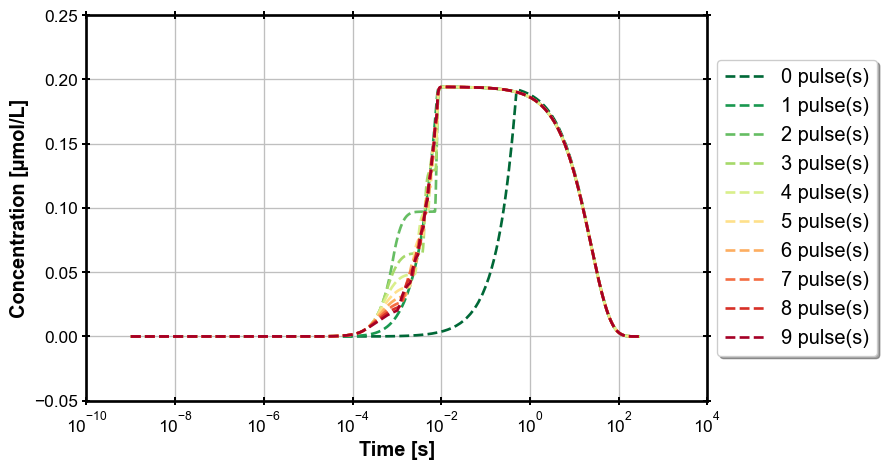

In [105]:
species = "ROO_r"
fig_man.set_brewer_map("RdYlGn", "diverging", 10, reverse=True)
with fig_man.open(f"Comparison of {species}") as (fig, ax):
    for period, df in sims.items():
        ax.plot(df.index, df[species], label=f"{period} pulse(s)", marker="")

    #ax.set_ylim(bottom=1e-6, top=2)
    #ax.set_xlim([1e-6, RIGHT_LIMIT])
    #ax.set_xlim([0, 100])
    ax.set_xscale("log")
    #ax.set_yscale("log")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Concentration [µmol/L]")
    RPlot.set_legend_right(ax)
    #ax.legend(fancybox=True, framealpha=1)
    #ax.set_title("Biology related species")
    save_fig(fig, "CC__time__ROO_r")

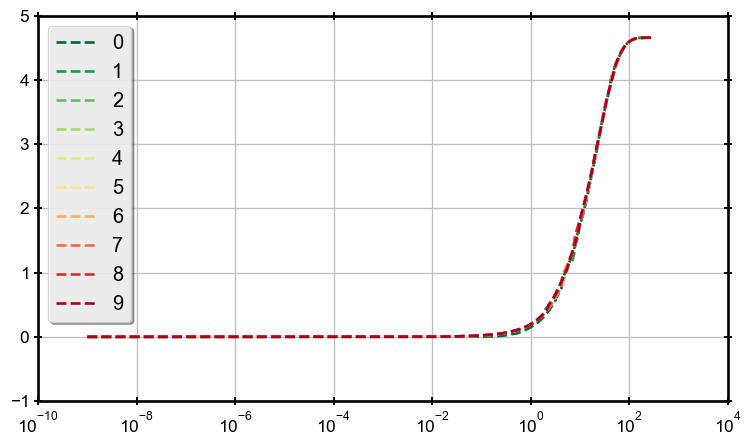

In [107]:
species = "ROO_r"
with fig_man.open(f"Cum Trapz{species}") as (fig, ax):
    for period, df in sims.items():
        ax.plot(df.index[:-1], cumulative_trapezoid(x=df.index.values,y=df["ROO_r"]), label=f"{period}", marker="")
    ax.legend()
    ax.set_xscale('log')
    #ax.set_yscale('log')

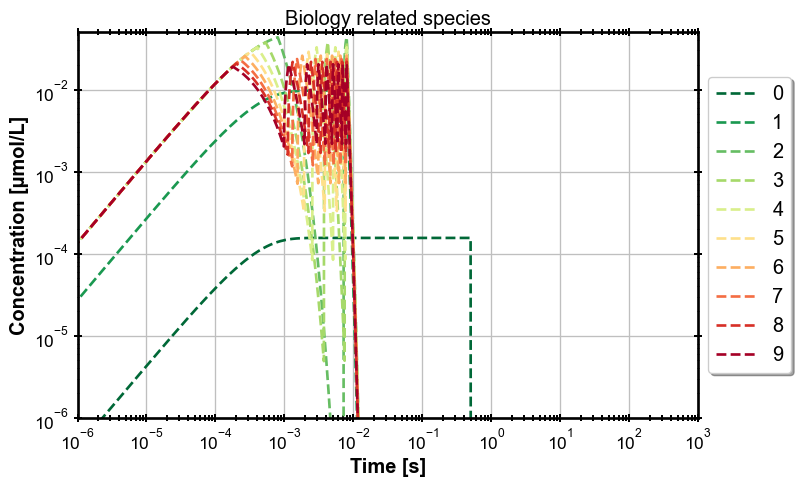

In [108]:
species = "R_r"
with fig_man.open(f"Comparison of {species}") as (fig, ax):
    for period, df in sims.items():
        ax.plot(df.index, df[species], label=f"{period}", marker="")

    ax.set_ylim(bottom=1e-6)
    ax.set_xlim([1e-6, RIGHT_LIMIT])
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Concentration [µmol/L]")
    RPlot.set_legend_right(ax)
    #ax.legend(fancybox=True, framealpha=1)
    ax.set_title("Biology related species")

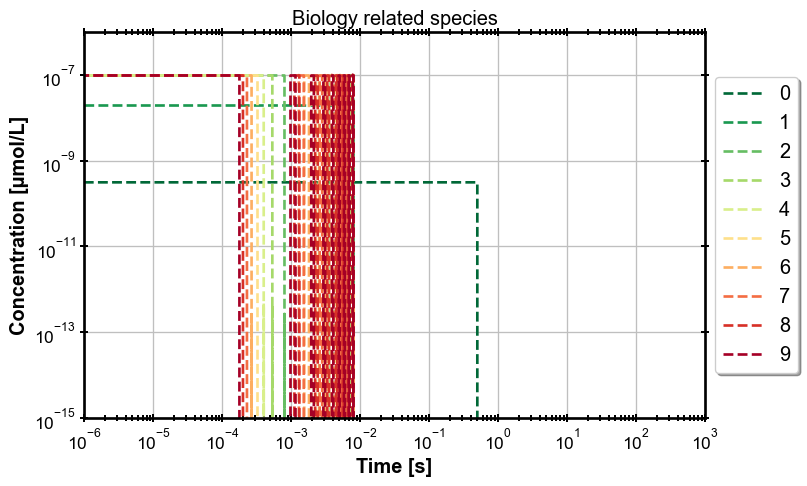

In [109]:
species = "OH_r"
with fig_man.open(f"Comparison of {species}") as (fig, ax):
    for period, df in sims.items():
        ax.plot(df.index, df[species], label=f"{period}", marker="")

    #ax.set_ylim(bottom=1e-6, top=1e2)
    ax.set_xlim([1e-6, RIGHT_LIMIT])
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Concentration [µmol/L]")
    RPlot.set_legend_right(ax)
    #ax.legend(fancybox=True, framealpha=1)
    ax.set_title("Biology related species")

#### O2

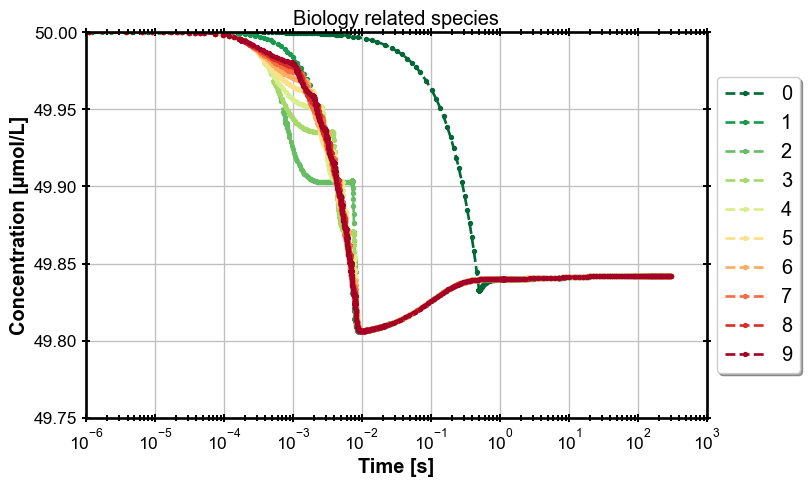

In [110]:
species = "O2"
with fig_man.open(f"Comparison of {species}") as (fig, ax):
    for period, df in sims.items():
        ax.plot(df.index, df[species], label=f"{period}", marker=".")

    ax.set_ylim(top=50)
    ax.set_xlim([1e-6, RIGHT_LIMIT])
    #ax.set_xlim([10, 25])
    ax.set_xscale("log")
    #ax.set_yscale("log")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Concentration [µmol/L]")
    RPlot.set_legend_right(ax)
    #ax.legend(fancybox=True, framealpha=1)
    ax.set_title("Biology related species")

## Compare Chemical reaction rates

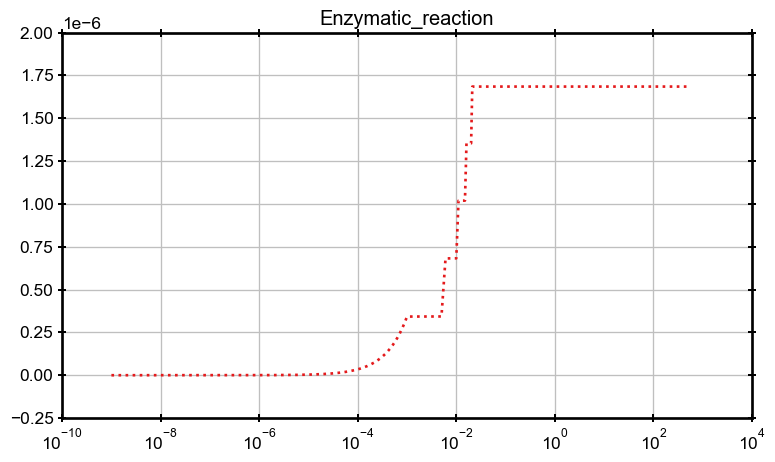

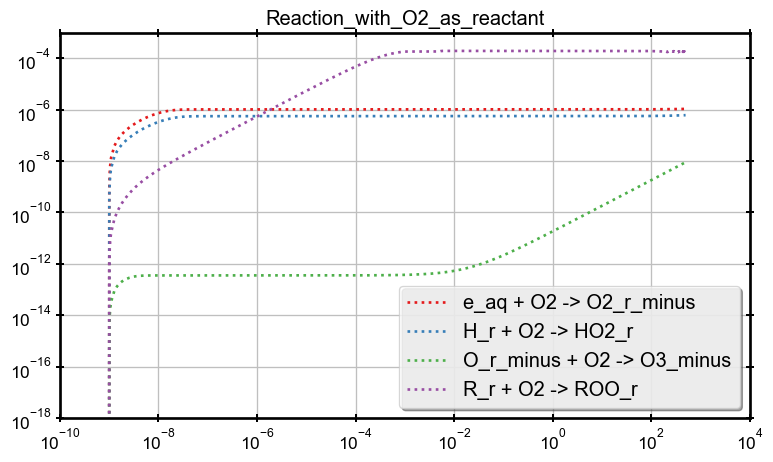

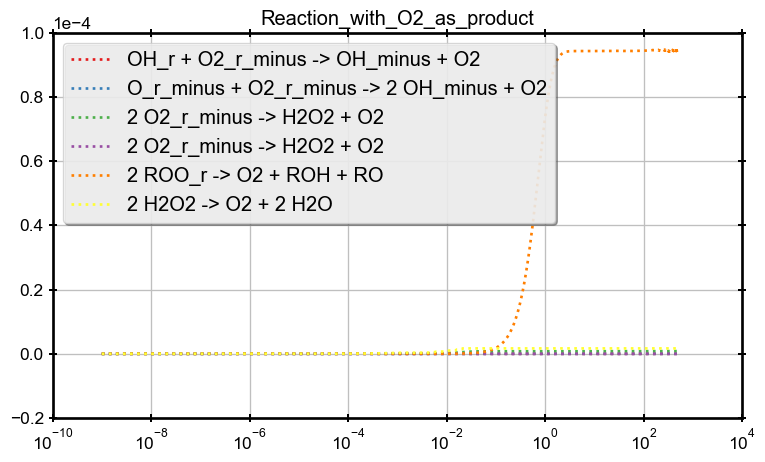

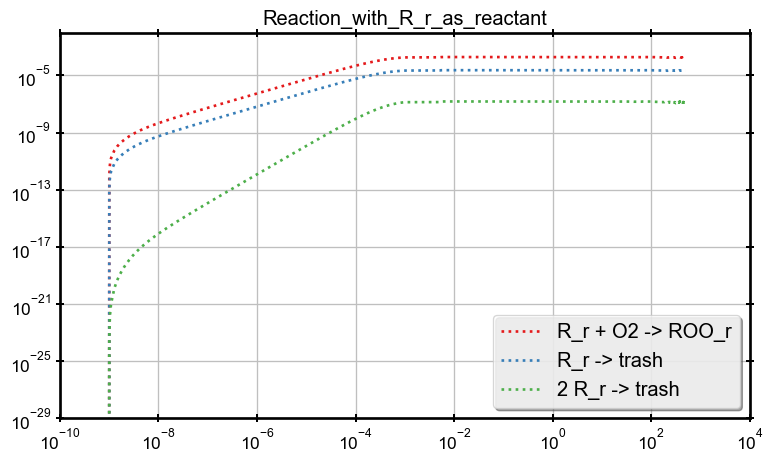

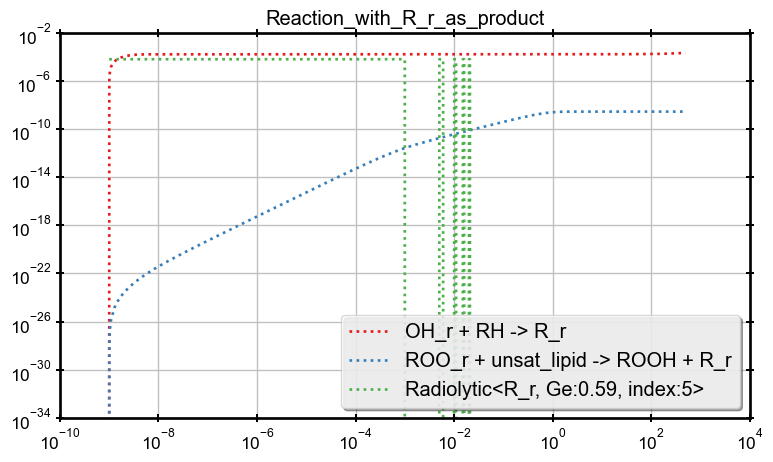

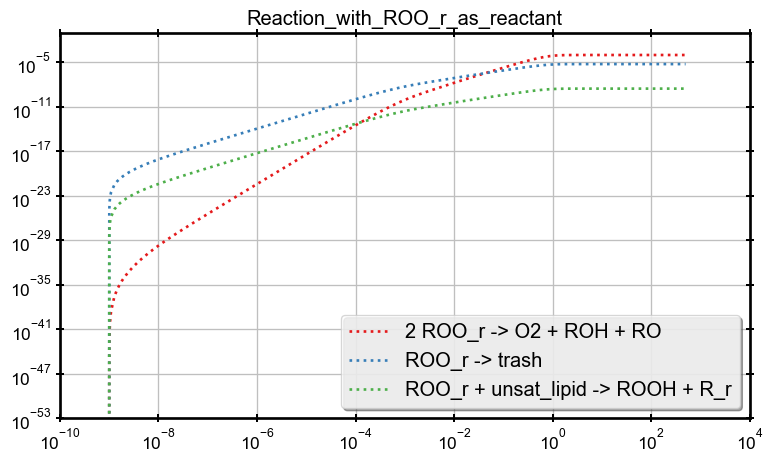

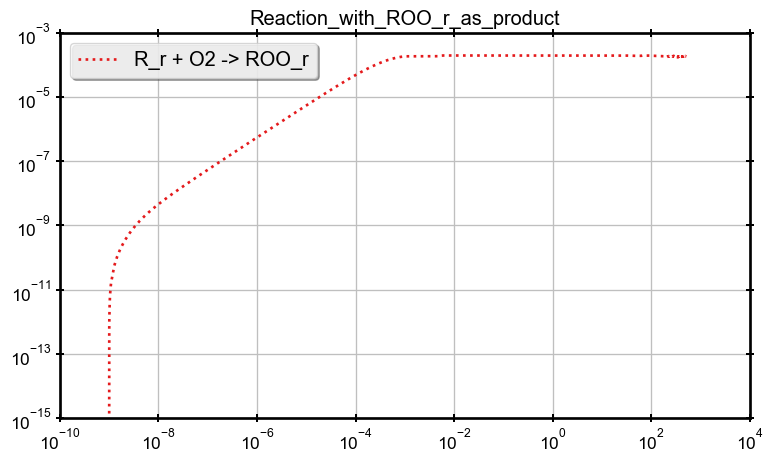

C:\Users\rtonneau\AppData\Local\Temp\ipykernel_18404\1964718746.py:60: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  ax.set_yscale("log")


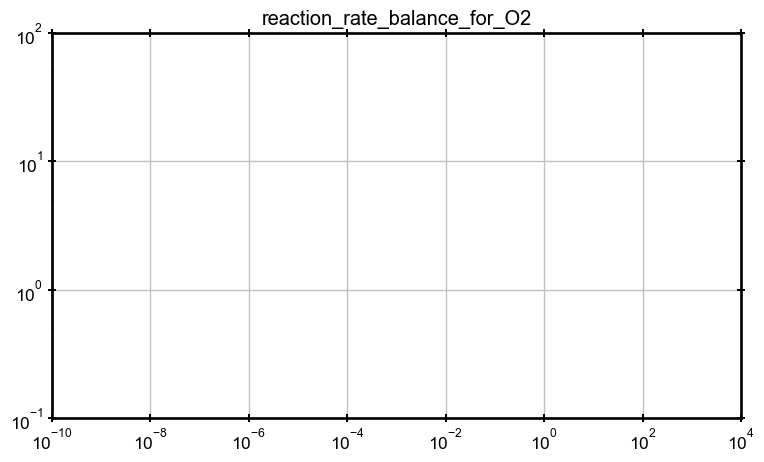

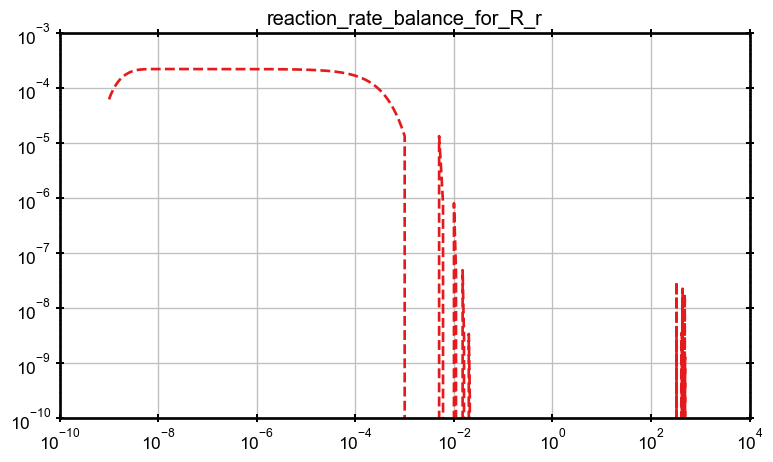

In [15]:
res = all_res[5e-3]
df_r = res.reconstruct_reactions()
df_b = res.species_balance_evolution()

fig_man.set_brewer_map("Set1", "qualitative", 6, reverse=False)

with fig_man.open(f"Enzymatic reaction") as (fig, ax):
    ax.semilogx(df_r.index, df_r["EZ_0"], label="fEZ_0", marker="", linestyle=":")
    ax.set_title(fig_man.last)

        
with fig_man.open(f"Reaction with O2 as reactant") as (fig, ax):
    for reaction in res.env.reactions_involving_reactant("O2"):
        ax.semilogx(df_r.index, df_r[reaction.as_label()], label=f"{reaction}", marker="", linestyle=":")
        ax.legend()
        ax.set_title(fig_man.last)
        ax.set_yscale("log")

with fig_man.open(f"Reaction with O2 as product") as (fig, ax):
    for reaction in res.env.reactions_involving_product("O2"):
        ax.semilogx(df_r.index, df_r[reaction.as_label()], label=f"{reaction}", marker="", linestyle=":")
        ax.legend()
        ax.set_title(fig_man.last)


with fig_man.open(f"Reaction with R_r as reactant") as (fig, ax):
    for reaction in res.env.reactions_involving_reactant("R_r"):
        ax.semilogx(df_r.index, df_r[reaction.as_label()], label=f"{reaction}", marker="", linestyle=":")
    ax.legend()
    ax.set_title(fig_man.last)
    ax.set_yscale("log")
    

with fig_man.open(f"Reaction with R_r as product") as (fig, ax):
    for reaction in res.env.reactions_involving_product("R_r"):
        ax.semilogx(df_r.index, df_r[reaction.as_label()], label=f"{reaction}", marker="", linestyle=":")
    ax.legend()
    ax.set_title(fig_man.last)
    ax.set_yscale("log")

with fig_man.open(f"Reaction with ROO_r as reactant") as (fig, ax):
    for reaction in res.env.reactions_involving_reactant("ROO_r"):
        ax.semilogx(df_r.index, df_r[reaction.as_label()], label=f"{reaction}", marker="", linestyle=":")
    ax.legend()
    ax.set_title(fig_man.last)
    ax.set_yscale("log")
    

with fig_man.open(f"Reaction with ROO_r as product") as (fig, ax):
    for reaction in res.env.reactions_involving_product("ROO_r"):
        ax.semilogx(df_r.index, df_r[reaction.as_label()], label=f"{reaction}", marker="", linestyle=":")
    ax.legend()
    ax.set_title(fig_man.last)
    ax.set_yscale("log")

    
with fig_man.open(f"reaction rate balance for O2") as (fig, ax):
    ax.semilogx(df_b.index, df_b["O2"], marker="")
    ax.set_title(fig_man.last)
    ax.set_yscale("log")

with fig_man.open(f"reaction rate balance for R_r") as (fig, ax):
    ax.semilogx(df_b.index, df_b["R_r"], marker="")
    ax.set_title(fig_man.last)
    ax.set_yscale("log")

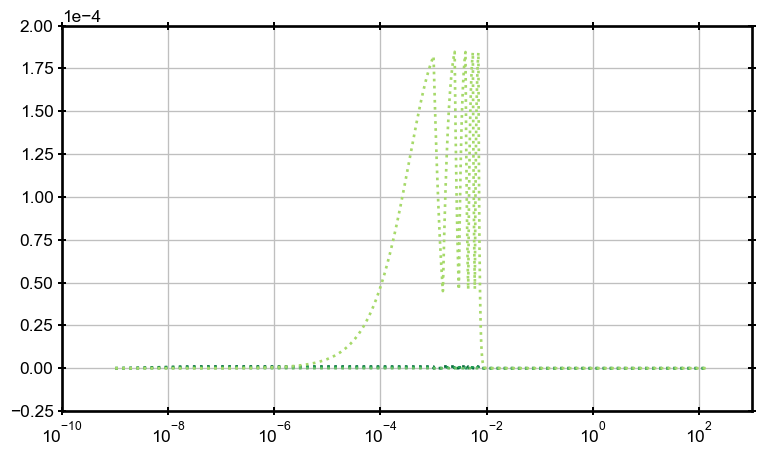

In [71]:
res = all_res[5e-3]
with fig_man.open(f"Reaction with R_r as product") as (fig, ax):
    df_r = all_res[1.5e-3].reconstruct_reactions()
    for reaction in res.env.reactions_involving_product("R_r"):
        ax.semilogx(df_r.index, df_r[reaction.as_label()], label=f"{reaction}", marker="", linestyle=":")

## Compare Pulses

**Integrate values per pulse**

In [51]:
by_pulse = pd.DataFrame(columns=df.columns)
for pulse in range(int(PULSES_NUMBER)):
    by_pulse.loc[pulse, :] = res.integrate_species(start=pulse*uc.beam.timer.period, stop=(pulse+1)*uc.beam.timer.period)

NameError: name 'PULSES_NUMBER' is not defined

In [33]:
by_pulse

,OH_r,O_r_minus,H2O2,HO2_minus,HO2_r,O2_r_minus,e_aq,H_r,H2,O2,O2_minus_minus,O3_minus,Fe_plus_plus_plus,RH_r,R_r,ROO_r,ROH,RO,ROOH
0,0.0,0.0,0.000038,0.0,0.0,0.000002,0.0,0.0,0.000063,9.999233,0.0,0.0,0.0,0.000285,0.000001,0.000615,0.0,0.0,0.0
1,0.0,0.0,0.000044,0.0,0.0,0.000004,0.0,0.0,0.000127,9.999921,0.0,0.000039,0.0,0.00053,0.0,0.000683,0.0,0.0,0.0
2,0.0,0.0,0.000044,0.0,0.0,0.000006,0.0,0.0,0.00019,9.999363,0.0,0.000137,0.0,0.000775,0.0,0.000747,0.0,0.0,0.0
3,0.0,0.0,0.000045,0.0,0.0,0.000007,0.0,0.0,0.000253,9.999367,0.0,0.000272,0.0,0.001022,0.0,0.000829,0.0,0.0,0.0
4,0.0,0.0,0.000044,0.0,0.0,0.000009,0.0,0.0,0.000315,9.953993,0.0,0.000429,0.0,0.001263,0.0,0.000911,0.0,0.0,0.0


### ON time

NameError: name 'by_pulse' is not defined

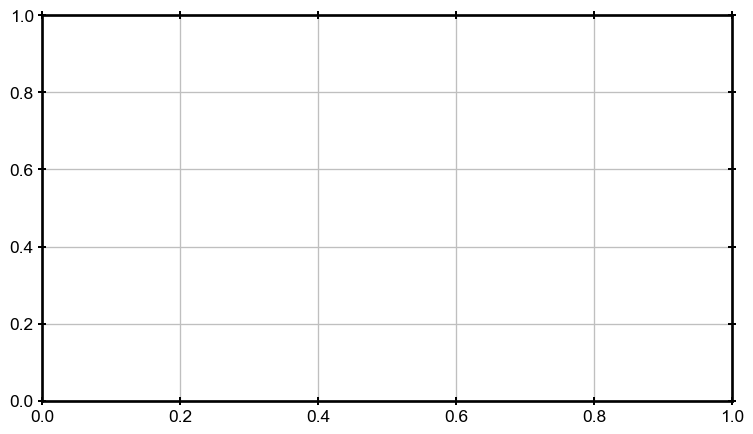

In [50]:
with fig_man.open(f"Pulse Integral") as (fig, ax):
    ax.plot(by_pulse.index+1, by_pulse["ROO_r"], label="ROO_r")
    ax.legend()

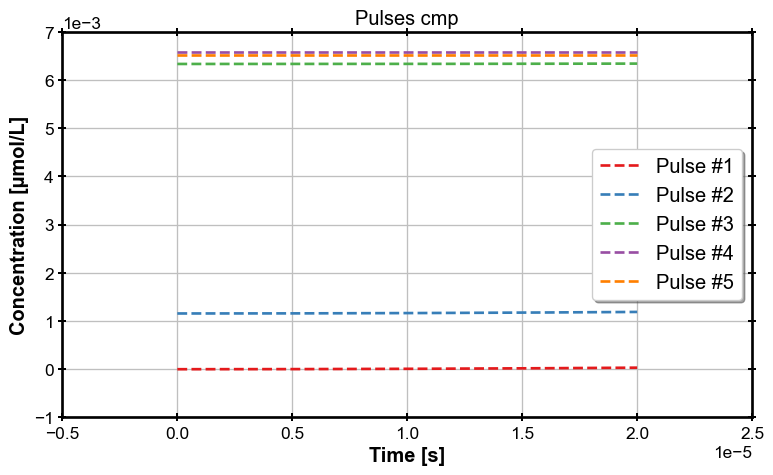

In [27]:
species = "ROO_r"
with fig_man.open(f"Pulses cmp") as (fig, ax):
    for pulse in range(int(PULSES_NUMBER)):
        start_pulse = pulse*uc.beam.timer.period
        mask = (df.index>=start_pulse) & (df.index < start_pulse+uc.beam.timer.on_time)
        ax.plot(df.index[mask]-start_pulse, df.loc[mask, species], label=f"Pulse #{pulse+1}", marker="")

    #ax.set_ylim(bottom=1e-6, top=100)
    #ax.set_xlim([1e-6,1])
    #ax.set_xscale("log")
    #ax.set_yscale("log")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Concentration [µmol/L]")
    ax.legend(fancybox=True, framealpha=1)
    ax.set_title("Pulses cmp")

### OFF Time

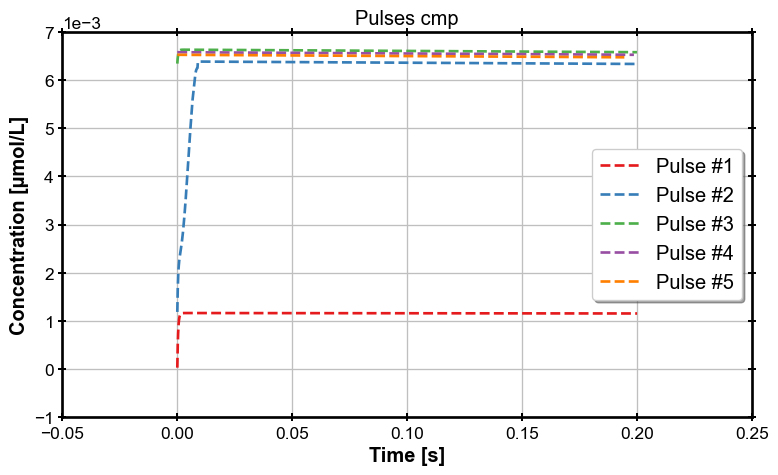

In [28]:
species = "ROO_r"
with fig_man.open(f"Pulses cmp") as (fig, ax):
    for pulse in range(int(PULSES_NUMBER)):
        start_pulse = pulse*uc.beam.timer.period + uc.beam.timer.on_time
        mask = (df.index>=start_pulse) & (df.index < (pulse+1)*uc.beam.timer.period)
        ax.plot(df.index[mask]-start_pulse, df.loc[mask, species], label=f"Pulse #{pulse+1}", marker="")

    #ax.set_ylim(bottom=1e-6, top=100)
    #ax.set_xlim([1e-6,0.12])
    #ax.set_xscale("log")
    #ax.set_yscale("log")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Concentration [µmol/L]")
    ax.legend(fancybox=True, framealpha=1)
    ax.set_title("Pulses cmp")